# Ingresos: conciliación, periodicidad y contaminación

## Resumen de la ejecución

Datos sintéticos; resultados de esta ejecución:

- **Abonos brutos (COP):** 10000000
- **Ingreso elegible (COP):** 3000000
- **Sobreestimación por sumar abonos:** 3.333
- **Conversiones reconciliadas:** 5

Los supuestos, límites y contraejemplos se explican junto a cada experimento.

## Objetivo y método

¿Una entrada de dinero representa ingreso disponible? Construimos un caso contable verificable, probamos conversiones de periodicidad y medimos sensibilidad de la normalización a contaminación.

### Supuestos y población

Un período mensual y una moneda. Las categorías de flujo se conocen por construcción. En producción requieren evidencia, reglas de conciliación y fuentes independientes; no se infiere intención del cliente.

Todos los datos son sintéticos. Las cifras ilustran mecanismos y no constituyen desempeño observado en una entidad. Fecha de desarrollo: 21 de octubre de 2026.

## Entorno reproducible

Ejecutar en orden, desde esta carpeta o una subcarpeta de la línea de fraude. La semilla y los parámetros quedan en las celdas; no se consulta internet ni se leen datos de clientes.

In [1]:
%matplotlib inline
from pathlib import Path
import sys, math, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.metrics import average_precision_score, brier_score_loss
base = next(p for p in [Path.cwd(), *Path.cwd().parents] if p.name == 'fraud-and-anomaly-research')
sys.path.insert(0, str(base / 'loss-minimization-engine'))
from src.engine import Case, Action, Scenario, optimize, expected_cost, shared_entity_count
rng = np.random.default_rng(20261021)
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({'figure.figsize': (8, 4.5), 'figure.dpi': 120, 'font.size': 11,
                     'axes.spines.top': False, 'axes.spines.right': False, 'grid.alpha': .25})
BLUE, TEAL, GOLD, PURPLE = '#386A96', '#217A72', '#B37D2E', '#73579D'
pd.options.display.float_format = '{:,.4f}'.format

No event loop hook running.


## 1. Conciliar antes de modelar


$$I_{mes}=\sum_{j\in\mathrm{ingresos\ elegibles}}F_j,\quad \mathrm{abonos\ brutos}=I_{mes}+\mathrm{traslados}+\mathrm{créditos}+\mathrm{otros}.$$

Una transferencia entre cuentas propias y un desembolso de préstamo no son ingreso laboral. Sumar ambos al ingreso puede crear capacidad de pago ficticia.

,tipo,monto_COP,elegible_ingreso
0,salario,1500000,True
1,traslado propio,2000000,False
2,préstamo,5000000,False
3,salario,1500000,True


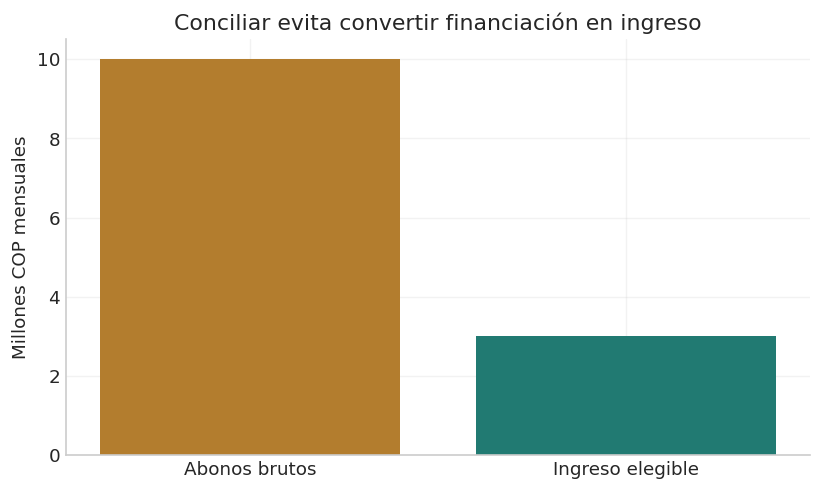

In [2]:
flows=pd.DataFrame({'tipo':['salario','traslado propio','préstamo','salario'],
                    'monto_COP':[1_500_000,2_000_000,5_000_000,1_500_000],
                    'elegible_ingreso':[True,False,False,True]})
gross=flows['monto_COP'].sum();eligible=flows.loc[flows['elegible_ingreso'],'monto_COP'].sum()
display(flows)
fig,ax=plt.subplots();ax.bar(['Abonos brutos','Ingreso elegible'],[gross/1e6,eligible/1e6],color=[GOLD,TEAL])
ax.set(ylabel='Millones COP mensuales',title='Conciliar evita convertir financiación en ingreso');plt.show()

El ejemplo expone un error de definición y no demuestra fraude. Una categoría mal etiquetada es un problema del contrato de datos antes de ser un problema del clasificador.

## 2. Periodicidad y pruebas dimensionales


$$I_{mensual}=I_{anual}/12=2I_{quincenal}=I_{semanal}\,52/12.$$

Quincenal se define aquí como dos pagos al mes, no cada 14 días. En este último caso el factor anualizado sería 26/12. Registrar la convención evita reconciliaciones falsas.

In [3]:
def monthly(amount,period):
    factors={'mensual':1.,'anual':1/12,'quincenal':2.,'semanal':52/12,'cada_14_días':26/12}
    if period not in factors or not np.isfinite(amount) or amount<0:raise ValueError('Monto/período inválido')
    return amount*factors[period]
conversions=pd.DataFrame({'periodo':['mensual','anual','quincenal','semanal','cada_14_días'],
                          'monto_COP':[3_000_000,36_000_000,1_500_000,3_000_000*12/52,3_000_000*12/26]})
conversions['mensual_COP']=[monthly(a,p) for a,p in zip(conversions['monto_COP'],conversions['periodo'])]
display(conversions)

,periodo,monto_COP,mensual_COP
0,mensual,"3,000,000.0000","3,000,000.0000"
1,anual,"36,000,000.0000","3,000,000.0000"
2,quincenal,"1,500,000.0000","3,000,000.0000"
3,semanal,"692,307.6923","3,000,000.0000"
4,cada_14_días,"1,384,615.3846","3,000,000.0000"


El redondeo debe aplicarse al presentar o según contrato, no antes de toda conversión. El mismo flujo observado no debe sumarse dos veces por estar en dos cuentas o dos extracciones.

## 3. Media y escala robusta ante contaminación


Para evidencia comparable de log ingreso, $z_{rob}=(x-\mathrm{mediana})/(1,4826\,MAD)$ y $MAD=\mathrm{mediana}|x-\mathrm{mediana}|$.

El factor 1,4826 aproxima la desviación normal cuando el supuesto es apropiado. La robustez de una estadística no verifica autenticidad de documentos ni justifica un umbral universal.

,contaminacion,metodo,alarma_legitimos,deteccion_desplazamiento,centro_log,escala_log
0,0.0000,media/desviación,0.0012,0.5550,14.9139,0.1879
1,0.0000,mediana/MAD,0.0012,0.5550,14.9161,0.1870
2,0.0500,media/desviación,0.0000,0.0000,15.0139,0.4762
3,0.0500,mediana/MAD,0.0000,0.3950,14.9301,0.2058
4,0.1000,media/desviación,0.0000,0.0000,15.1139,0.6350
5,0.1000,mediana/MAD,0.0000,0.2950,14.9381,0.2176
6,0.2000,media/desviación,0.0000,0.0000,15.3139,0.8274
7,0.2000,mediana/MAD,0.0000,0.1350,14.9663,0.2551
8,0.3500,media/desviación,0.0000,0.0000,15.6139,0.9773
9,0.3500,mediana/MAD,0.0000,0.0000,15.0415,0.4112


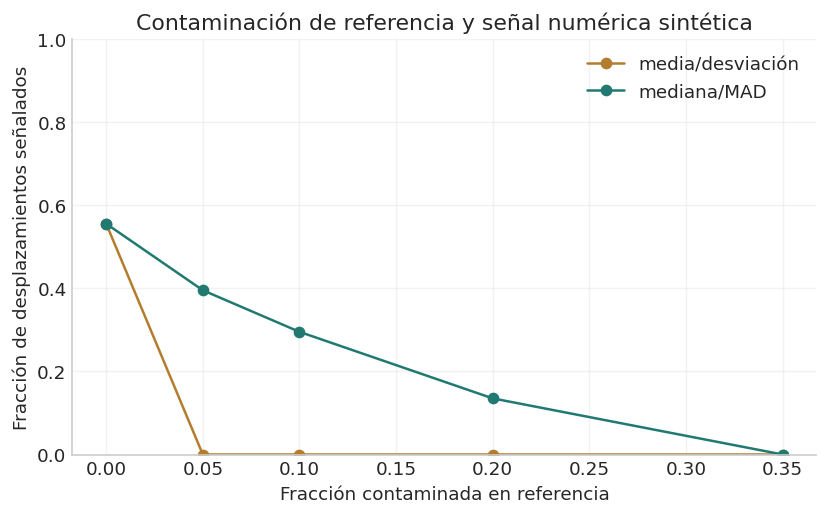

In [4]:
clean=rng.normal(np.log(3_000_000),.18,1000)
legitimate_test=rng.normal(np.log(3_000_000),.18,800)
shifted_test=rng.normal(np.log(3_000_000)+.6,.18,200)
records=[]
for contamination in [0,.05,.1,.2,.35]:
    mixed=clean.copy();count=int(contamination*len(mixed))
    mixed[:count]+=2.
    mean,sd=mixed.mean(),mixed.std(ddof=1)
    median=np.median(mixed);scale=1.4826*np.median(np.abs(mixed-median))
    for method,center,spread in [('media/desviación',mean,sd),('mediana/MAD',median,scale)]:
        # Threshold fixed before evaluation. Shifted examples are discrepancies,
        # not adjudicated fraud; 'detection' means a synthetic numeric shift.
        records.append({'contaminacion':contamination,'metodo':method,
                        'alarma_legitimos':np.mean((legitimate_test-center)/spread>3),
                        'deteccion_desplazamiento':np.mean((shifted_test-center)/spread>3),
                        'centro_log':center,'escala_log':spread})
robustness=pd.DataFrame(records);display(robustness.round(4))
fig,ax=plt.subplots()
for method,color in [('media/desviación',GOLD),('mediana/MAD',TEAL)]:
    subset=robustness[robustness['metodo']==method]
    ax.plot(subset['contaminacion'],subset['deteccion_desplazamiento'],marker='o',label=method,color=color)
ax.set(xlabel='Fracción contaminada en referencia',ylabel='Fracción de desplazamientos señalados',ylim=(0,1),title='Contaminación de referencia y señal numérica sintética');ax.legend();plt.show()

La curva evalúa un desplazamiento numérico, no fraude. El MAD también cambia con contaminación alta y con mezclas de actividades; segmentar y validar sigue siendo necesario. En caso de escala cero o población escasa se debe abstener o usar un fallback documentado.

## Comprobaciones y límites

Las identidades y contraejemplos siguientes son parte del experimento; no verifican desempeño productivo.

In [5]:
assert gross==10_000_000 and eligible==3_000_000
assert np.allclose(conversions['mensual_COP'],3_000_000)
assert np.isfinite(robustness.select_dtypes('number')).all().all()

## Resultados computados

In [6]:
metrics = {'Abonos brutos (COP)': int(gross), 'Ingreso elegible (COP)': int(eligible), 'Sobreestimación por sumar abonos': round(float(gross/eligible),3), 'Conversiones reconciliadas': len(conversions)}
print("LAB_METRICS:" + json.dumps(metrics, ensure_ascii=False))

LAB_METRICS:{"Abonos brutos (COP)": 10000000, "Ingreso elegible (COP)": 3000000, "Sobreestimación por sumar abonos": 3.333, "Conversiones reconciliadas": 5}


## Ideas y preguntas para continuar

1. Añadir trazabilidad entre cuenta origen y destino para deduplicar traslados.
2. Conciliar ingreso bruto, neto y ventas de negocio por separado.
3. Repetir el experimento con grupos multimodales y escalas casi cero.
4. Cuantificar efecto de ruido OCR sin llamar fraude a un error de extracción.
5. Evaluar el costo de pedir soportes adicionales frente a la información que aportan.

## Fuentes y relación con el proyecto

Derivaciones y flujos sintéticos construidos dentro del notebook. Las conversiones declaran su convención; las categorías de flujo no proceden de clientes. Modelo de referencia del proyecto: `../README.md`.

Consultar también `../README.md` y `../../MODEL_AND_LOSS_METHODS.md`.